<img src="https://datascientest.fr/train/assets/logo_liora.png" style="height:150px">

<hr style="border-width:2px;border-color:#75DFC1">
<center><h1> AI Engineers — Démo Part 2 </h1></center>
<center><h2> Tokens, embeddings et attention </h2></center>
<hr style="border-width:2px;border-color:#75DFC1">

> **Part 2 · 15 min · prépare le Lab 0**
> Avant la séance : `make install-demo`, puis lancer la démo une fois (télécharge CamemBERT, 450 Mo).

![](assets/02_pipeline.png)

In [1]:
# Import operating-system utilities to read environment variables.
import os

# Import Matplotlib for plotting.
import matplotlib.pyplot as plt
# Import NumPy for numerical array operations.
import numpy as np
# Import the tokenizer library used by OpenAI models.
import tiktoken
# Import PyTorch for tensor operations and model inference.
import torch
# Import the helper that loads environment variables from a .env file.
from dotenv import load_dotenv
# Import the OpenAI-compatible embedding client.
from langchain_openai import OpenAIEmbeddings

# Import the pretrained transformer model and tokenizer loaders.
from transformers import AutoModel, AutoTokenizer

# Import the Transformers logging utilities.
from transformers.utils import logging

# loading env var
# Load environment variables from the .env file.
load_dotenv()

# setting looging error leval
# Show only error messages from the Transformers library.
logging.set_verbosity_error()

# loading embedding model
# Create the embedding client and disable automatic context-length checking.
embeddings = OpenAIEmbeddings(model="text-embedding-3-small", check_embedding_ctx_length=False,
                              # Read the API endpoint and API key from environment variables.
                              base_url=os.environ["LLM_BASE_URL"], api_key=os.environ["LLM_API_KEY"])

# loding transformer model tokenizer
# Load the tokenizer pretrained for the French CamemBERT model.
camembert_tok = AutoTokenizer.from_pretrained("almanach/camembert-base")

# loding transformer model
# Load CamemBERT and request attention weights in its outputs.
camembert = AutoModel.from_pretrained("almanach/camembert-base", output_attentions=True,
                                      # Use eager attention so the model can return attention matrices.
                                      attn_implementation="eager")
# Print a confirmation that initialization is complete.
print("Ready to start")

Ready to start


<hr style="border-width:2px;border-color:#75DFC1">
<center><h2 style = "text-align:center" > 1. La tokenisation </h2></center>
<hr style="border-width:2px;border-color:#75DFC1">

- **Le modèle ne lit pas des mots** : il lit des numéros de morceaux de mots.
- Deux tokenizers, **deux découpages** de la même phrase.

In [7]:

# Define the French sentence to tokenize.
sentence = "L'indemnité compensatrice de congés payés est versée au salarié à la fin de son contrat."

# Load the o200k_base encoding used by GPT-4o.
encoding_4o = tiktoken.get_encoding("o200k_base")

# Convert the sentence into a sequence of token IDs.
ids = encoding_4o.encode(sentence)

# Create an empty list to collect decoded token pieces.
pieces = []
# Iterate over each token ID in the encoded sentence.
for token_id in ids:
    # Decode the current token and append its text to the list.
    pieces.append(encoding_4o.decode([token_id]))


# Print the number of tokens produced by the GPT-4o encoding.
print("GPT-4o   :", len(ids), "tokens")

# Display the decoded token pieces list.
print(pieces, end='\n\n\n')

# Display the first eight token IDs as a short preview.
print("First 8 ids: ", ids[:8], "...")

# Tokenize the same sentence with CamemBERT and extract its token IDs.
ids_camembert = camembert_tok(sentence)["input_ids"]

# Print the number of tokens produced by CamemBERT.
print("CamemBERT :", len(ids_camembert), "tokens")

# Convert the CamemBERT token IDs into readable token strings and print them.
print(camembert_tok.convert_ids_to_tokens(ids_camembert))

GPT-4o   : 23 tokens
['L', "'ind", 'emn', 'ité', ' compens', 'atrice', ' de', ' cong', 'és', ' pay', 'és', ' est', ' vers', 'ée', ' au', ' salarié', ' à', ' la', ' fin', ' de', ' son', ' contrat', '.']


First 8 ids:  [43, 82245, 133678, 3761, 18281, 48155, 334, 86177] ...
CamemBERT : 22 tokens
['<s>', '▁L', "'", 'indemnité', '▁comp', 'ens', 'atrice', '▁de', '▁congés', '▁payés', '▁est', '▁versée', '▁au', '▁salarié', '▁à', '▁la', '▁fin', '▁de', '▁son', '▁contrat', '.', '</s>']


- GPT-4o coupe **« indemnité » en 3** ; CamemBERT, entraîné sur du français, le garde **entier**.
- « compensatrice », trop rare, est **coupé par les deux**.
- Les numéros n'ont **aucun sens** en soi : le sens vient des vecteurs.

<hr style="border-width:2px;border-color:#75DFC1">
<center><h2 style = "text-align:center" > 2. Les embeddings </h2></center>
<hr style="border-width:2px;border-color:#75DFC1">

- 9 expressions, **3 thèmes** : repos, argent, transports.
- Proche par le sens = **proche dans l'espace**, même sans mot commun.

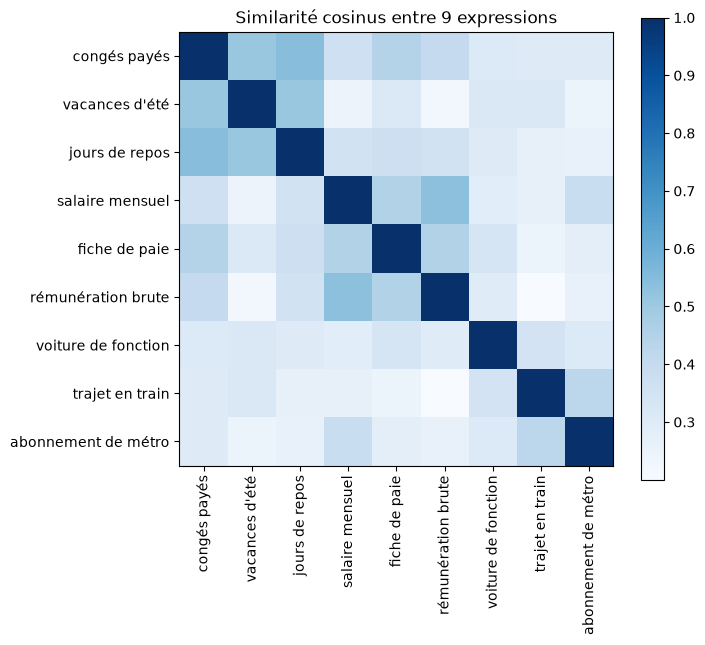

In [9]:
# Start the list with three expressions related to time off.
expressions = ["congés payés", "vacances d'été", "jours de repos",
               # Add three expressions related to salary and pay.
               "salaire mensuel", "fiche de paie", "rémunération brute",
               # Complete the list with three expressions related to transportation.
               "voiture de fonction", "trajet en train", "abonnement de métro"]

# Request an embedding for each expression and store the vectors in a NumPy array.
X = np.array(embeddings.embed_documents(expressions))

# Normalize each embedding to unit length, preserving the array shape.
X = X / np.linalg.norm(X, axis=1, keepdims=True)

# Compute pairwise cosine similarities by multiplying the normalized vectors.
similarities = X @ X.T

# Create a figure for the similarity heatmap.
plt.figure(figsize=(7, 6))

# Display the similarity matrix using a blue color scale.
plt.imshow(similarities, cmap="Blues")

# Label the columns with the expressions and rotate the labels vertically.
plt.xticks(range(len(expressions)), expressions, rotation=90)

# Label the rows with the expressions.
plt.yticks(range(len(expressions)), expressions)

# Add a color bar showing the similarity scale.
plt.colorbar()

# Set the title of the similarity heatmap.
plt.title("Similarité cosinus entre 9 expressions")

# Display the figure.
plt.show()

- **3 blocs foncés** : ≈ 0,5 dans un thème, ≈ 0,3 entre thèmes. **Personne n'a donné les thèmes** au modèle.
- On **compare** des similarités entre elles, jamais à un seuil absolu.
- Avec des mots isolés, les groupes deviennent flous : l'embedder  a été pensé à l'origine pour travailler avec du **texte**.

<hr style="border-width:2px;border-color:#75DFC1">
<center><h2 style = "text-align:center" > 3. L'attention </h2></center>
<hr style="border-width:2px;border-color:#75DFC1">

Prenons la phrase : **« Le salarié a posé ses congés car il était fatigué. »** Pour représenter « il » en contexte, le modèle peut récupérer de l'information sur les autres tokens, notamment « salarié ».

### Les couches se suivent, les têtes travaillent en parallèle

CamemBERT possède **12 couches, chacune avec ses propres 12 têtes**. Chaque token traverse **les 12 couches, dans l’ordre** : chaque couche reçoit son vecteur et en produit une nouvelle version. Tous les tokens avancent ainsi en parallèle.

```text
Phrase -> tokens -> embeddings + positions
                           |
                           v
                 Couche 0  [12 tetes]
                           |
                  Vecteurs mis a jour
                           |
                           v
                 Couche 1  [12 autres tetes]
                           |
                          ...
                           |
                           v
                 Couche 11 [12 autres tetes]
                           |
                           v
                 Un vecteur final par token
```

**Concrètement, pour « il » :** à la couche 0, son vecteur est mis à jour à partir des vecteurs d’entrée de la phrase. À la couche 1, il échange avec les vecteurs **déjà transformés par la couche 0**, et ainsi de suite. On ne repart donc pas des embeddings initiaux à chaque couche.

« Enrichir » ne signifie pas agrandir : **le vecteur garde la même taille**, mais son contenu est réorganisé ; certaines informations sont renforcées, d’autres atténuées. CamemBERT étant **bidirectionnel**, « il » peut porter son attention sur les tokens situés avant **et** après lui.

Dans une couche, les têtes reçoivent les **mêmes vecteurs**, mais utilisent des paramètres appris différents. Chacune calcule ses poids d'attention et récupère un mélange pondéré d'informations des tokens.

```text
            Vecteurs de tous les tokens
                        |
           +------------+------------+
           |            |            |
           v            v            v
        Tete 0       Tete 1  ...  Tete 11
           |            |            |
           v            v            v
      Contribution Contribution Contribution
        par token    par token    par token
           |            |            |
           +------------+------------+
                        |
                        v
          Concatenation + melange appris
                        |
                        v
         Ajouts residuels, normalisations
          et reseau applique par token
                        |
                        v
          Nouveaux vecteurs des tokens
                        |
                        v
                Couche suivante
```

### Ce que nous allons observer

Pour le token **« il »**, deux têtes d'une même couche peuvent attribuer des poids très différents à **« salarié »**. Nous allons comparer leurs cartes d'attention à la moyenne des 12 têtes, avec **la même échelle de couleurs**.

- Une carte montre les **poids d'attention**, pas les vecteurs produits par la tête.
- La moyenne peut diluer un motif visible dans une tête. **C'est notre résumé visuel, pas la façon dont le modèle combine les têtes.**
- Les comportements sont appris : une tête n'est pas un « spécialiste des pronoms » fixé à l'avance, et une carte seule ne prouve pas une compréhension grammaticale.

**À retenir : les têtes apportent différentes contributions en parallèle ; les couches retravaillent successivement le résultat.**


In [10]:
# Define a French sentence containing a pronoun and its possible antecedent.
sentence = "Le salarié a posé ses congés car il était fatigué."

# Tokenize the sentence and return PyTorch tensors.
inputs = camembert_tok(sentence, return_tensors="pt")

# Convert the token IDs for the first input sequence into readable strings.
tokens = camembert_tok.convert_ids_to_tokens(inputs["input_ids"][0])

# Disable gradient tracking during model inference.
with torch.no_grad():
    # Run CamemBERT on the tokenized sentence to obtain model outputs and attentions.
    outputs = camembert(**inputs)

# sortie.attentions : une matrice par couche, de forme (1, têtes, tokens, tokens)
# Select attention layer index 9, which is the tenth transformer layer.
layer = 9

# Extract all attention heads for the first input sequence at the selected layer.
attention = outputs.attentions[layer][0]

# Print the number of layers, attention heads, and input tokens.
print(len(outputs.attentions), "couches,", attention.shape[0], "têtes,", len(tokens), "tokens")

# Display the token strings used as attention-map labels.
print(tokens)

12 couches, 12 têtes, 13 tokens
['<s>', '▁Le', '▁salarié', '▁a', '▁posé', '▁ses', '▁congés', '▁car', '▁il', '▁était', '▁fatigué', '.', '</s>']


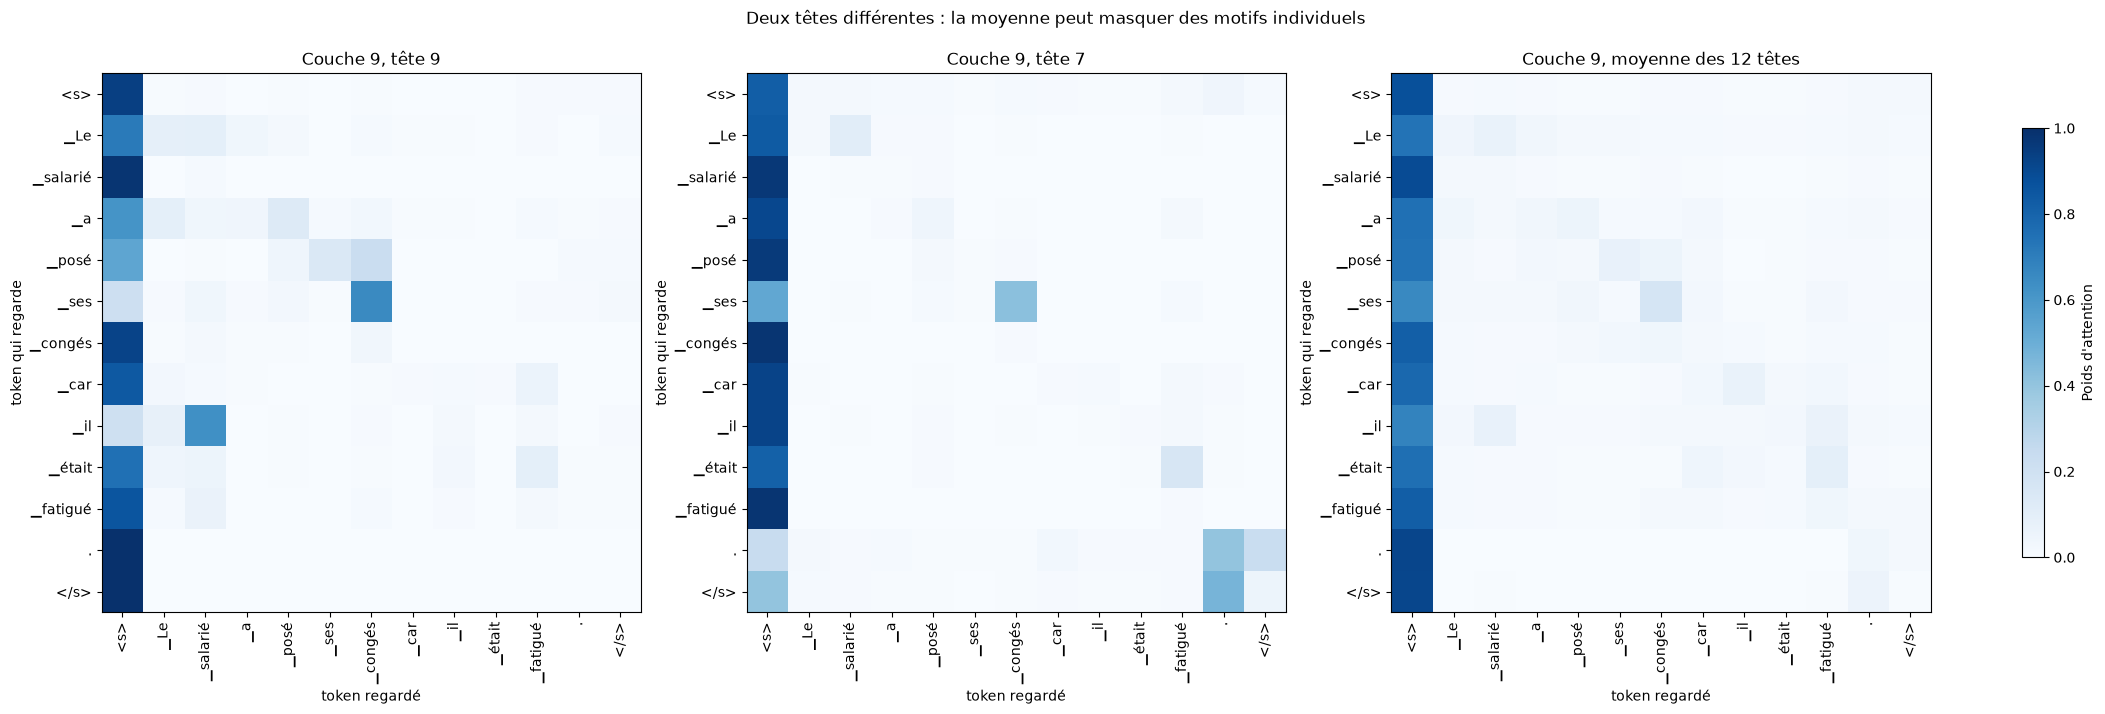

Indices à partir de 0 : couche 9, têtes 9 et 7.
Tête 7 : écart absolu moyen maximal avec la tête 9 sur cette phrase.
Poids de « salarié » vu depuis « il », tête 9 : 0.631
Poids de « salarié » vu depuis « il », tête 7 : 0.007
Poids de « salarié » vu depuis « il », moyenne des têtes : 0.075


In [13]:
# Keep head index 9 as the reference used in the original demonstration.
head_a = 9

# Measure the mean absolute difference between each head and the reference head.
head_differences = (attention - attention[head_a]).abs().mean(dim=(1, 2))

# Exclude the reference head from the selection of the second head.
head_differences[head_a] = -1

# Select the most different head for this sentence, not a predefined linguistic role.
head_b = int(head_differences.argmax().item())

# Average the attention matrices across all heads in the selected layer.
mean_attention = attention.mean(dim=0)

# Collect the two individual heads and the mean for side-by-side comparison.
maps = [attention[head_a], attention[head_b], mean_attention]

# Build titles using zero-based layer and head indices.
titles = [f"Couche {layer}, tête {head_a}", f"Couche {layer}, tête {head_b}",
          # Label the aggregate with the actual number of heads.
          f"Couche {layer}, moyenne des {attention.shape[0]} têtes"]

# Create three plots with enough space for the token labels and a shared color bar.
fig, axes = plt.subplots(1, 3, figsize=(21, 7), constrained_layout=True)

# Draw the individual heads and their aggregate using identical plotting settings.
for ax, matrix, title in zip(axes, maps, titles):
    # Use a fixed zero-to-one scale so colors mean the same thing in every panel.
    image = ax.imshow(matrix.numpy(), cmap="Blues", vmin=0, vmax=1)
    # Identify the head or aggregate shown in this panel.
    ax.set_title(title)
    # Label columns with the tokens receiving attention.
    ax.set_xticks(range(len(tokens)), tokens, rotation=90)
    # Label rows with the tokens assigning attention.
    ax.set_yticks(range(len(tokens)), tokens)
    # Name the horizontal axis.
    ax.set_xlabel("token regardé")
    # Name the vertical axis.
    ax.set_ylabel("token qui regarde")

# Add one color bar shared by all three attention maps.
fig.colorbar(image, ax=axes, label="Poids d'attention", shrink=0.7)
# State the comparison without claiming that attention proves a linguistic role.
fig.suptitle("Deux têtes différentes : la moyenne peut masquer des motifs individuels")
# Display the three attention maps.
plt.show()

# Find the position of the pronoun token in the input sequence.
il_idx = tokens.index("▁il")

# Find the position of the employee token in the input sequence.
salarie_idx = tokens.index("▁salarié")

# Explain how the second head was chosen for this particular input.
print(f"Indices à partir de 0 : couche {layer}, têtes {head_a} et {head_b}.")

# Make the data-dependent selection criterion explicit.
print(f"Tête {head_b} : écart absolu moyen maximal avec la tête {head_a} sur cette phrase.")

# Compare the same pronoun-to-employee attention weight in all three panels.
for matrix, label in zip(maps, [f"tête {head_a}", f"tête {head_b}", "moyenne des têtes"]):
    # Print the attention weight with enough precision to reveal differences.
    print(f"Poids de « salarié » vu depuis « il », {label} : {matrix[il_idx, salarie_idx].item():.3f}")


- Ligne = le token qui regarde · case = le poids donné · **chaque ligne somme à 1**.
- Tête 9 : **« il » → « salarié » (0,63)**, et « ses » → « congés ».
- Colonne `<s>` foncée : la tête **n'a rien de particulier à relier**.
- La **moyenne des têtes efface le lien** : d'où plusieurs têtes par couche.

<hr style="border-width:2px;border-color:#75DFC1">
<center><h2 style = "text-align:center" > 4. L'encodage de position </h2></center>
<hr style="border-width:2px;border-color:#75DFC1">

Il reste un problème. L'attention regarde **tous les mots en même temps**, comme si on vidait la phrase dans un sac. Pour elle, « le chien mord l'homme » et « l'homme mord le chien », c'est **le même sac**. Le sens a pourtant changé du tout au tout.

La solution est simple : avant d'entrer dans le modèle, chaque token reçoit **son numéro de place**. Mais ce numéro n'est pas écrit comme « 1, 2, 3… ». Il est écrit avec **plusieurs chiffres**, un peu comme **une date** : le **jour** change tous les jours, le **mois** tous les 30 jours, l'**année** tous les 365 jours. Aucun chiffre ne suffit seul ; ensemble, ils désignent un jour unique.

Commençons par la version la plus simple de cette idée : écrire la position **en binaire**.

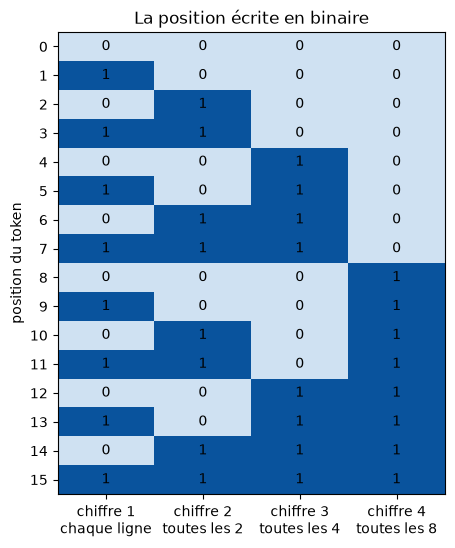

In [ ]:
# Set the number of token positions to write in binary.
binary_positions = 16
# Set the number of binary digits, enough to write 0 to 15.
digits = 4

# Write each position as its binary digits, the fastest-changing digit first.
binary = np.array([[(pos // 2**d) % 2 for d in range(digits)] for pos in range(binary_positions)])

# Create a figure for the binary table.
plt.figure(figsize=(5, 6))
# Display the digits as a two-color table.
plt.imshow(binary, cmap="Blues", aspect="auto", vmin=-0.3, vmax=1.2)
# Iterate over every position.
for pos in range(binary_positions):
    # Iterate over every digit of the position.
    for d in range(digits):
        # Write the digit inside its cell.
        plt.text(d, pos, binary[pos, d], ha="center", va="center")
# Name each column with how often its digit changes.
plt.xticks(range(digits), ["chiffre 1\nchaque ligne", "chiffre 2\ntoutes les 2", "chiffre 3\ntoutes les 4", "chiffre 4\ntoutes les 8"])
# Show every position on the vertical axis.
plt.yticks(range(binary_positions))
# Label the vertical axis with the token position.
plt.ylabel("position du token")
# Set the title of the binary table.
plt.title("La position écrite en binaire")
# Display the figure.
plt.show()

Chaque ligne est **la signature d'une position**. Le token 1 s'écrit 1 0 0 0, le token 6 s'écrit 0 1 1 0, et aucune ligne ne ressemble exactement à une autre.

Regardez les colonnes. **À gauche, le premier chiffre clignote** à chaque ligne, comme le jour sur le calendrier. **À droite, le dernier chiffre ne bouge que toutes les 8 lignes**, comme l'année. Les chiffres rapides distinguent deux voisins ; les chiffres lents situent le token dans un ensemble plus grand.

Le Transformer reprend exactement cette idée, avec une différence : au lieu de sauter brutalement entre 0 et 1, ses chiffres **glissent en douceur**, comme des vagues. Résultat : deux positions voisines reçoivent des signatures **proches**, et le modèle peut « sentir » la distance entre deux mots. Voici ce que ça donne sur 50 positions.

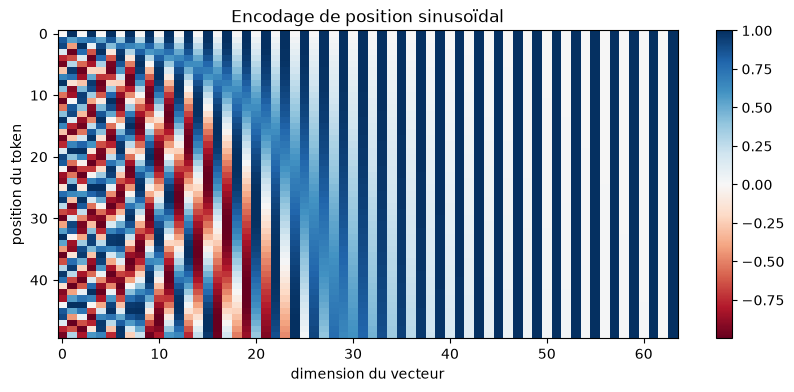

In [7]:
# Set the number of token positions to visualize.
positions = 50
# Set the dimensionality of each positional encoding vector.
dimension = 64

# Initialize the positional encoding matrix with zeros.
encoding = np.zeros((positions, dimension))
# Iterate over every token position.
for pos in range(positions):
    # Iterate over the embedding dimensions in even-odd pairs.
    for i in range(0, dimension, 2):
        # Compute the position-dependent angle for the current frequency.
        angle = pos / (10000 ** (i / dimension))
        # Store the sine component in the even-indexed dimension.
        encoding[pos, i] = np.sin(angle)
        # Store the cosine component in the next odd-indexed dimension.
        encoding[pos, i + 1] = np.cos(angle)

# Create a figure for the positional encoding heatmap.
plt.figure(figsize=(10, 4))
# Display the encoding matrix with a diverging color scale and automatic aspect ratio.
plt.imshow(encoding, cmap="RdBu", aspect="auto")
# Label the horizontal axis with the vector dimension.
plt.xlabel("dimension du vecteur")
# Label the vertical axis with the token position.
plt.ylabel("position du token")
# Add a color bar showing the encoding values.
plt.colorbar()
# Set the title of the positional encoding heatmap.
plt.title("Encodage de position sinusoïdal")
# Display the figure.
plt.show()

On retrouve **le même motif que le binaire**. Chaque ligne est la signature d'une position ; chaque colonne est un « chiffre ».

À gauche, le **damier** : des chiffres rapides, qui changent à chaque token et séparent deux **voisins**. Au milieu, des **vagues** de plus en plus larges. À droite, des **bandes droites** : des chiffres si lents qu'ils ont à peine bougé sur 50 tokens. Ils ne servent pas ici ; ils prendront le relais sur des **textes de plusieurs milliers de tokens**.

Le modèle **ajoute** cette signature au vecteur de chaque token. Désormais, « chien » en 2e position et « chien » en 5e position ne sont plus tout à fait le même vecteur. Les modèles récents utilisent une variante, **RoPE**, qui repose sur la même idée.

> « Le modèle lit tous les mots en même temps, donc il ne sait pas dans quel ordre ils sont. On colle sur chaque mot son numéro de place, écrit comme une date : des chiffres qui changent vite, d'autres lentement. Ce graphique, c'est la liste de ces numéros. »

**→ Lab 0** : compter des tokens avec deux tokenizers, calculer des similarités.